# Issue #229 — divergence-aware M×3 data profile (BJ-UNIFIED-DIVERGENCE-DATA-PROFILE-001)

REWORK 2026-08-15 (REWORK_TYPE=method).  This notebook is a thin readable
orchestration layer: it runs the reusable `src/divergence_profile` package
top-to-bottom, renders every committed machine-readable table/figure and
verifies the immutable package.  All durable evidence lives in
`results/bj229_divergence_profile_v1/`.

## Setup

Run from the repository root with the project's pinned environment
(`PYTHONPATH=src .venv/bin/python`).  The package reads only the four
accepted upstream frozen packages (#203/#204/#214/#180), each
SHA256-verified before use; no settlement/result table is opened.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# Notebook may be executed from the repo root or from its own directory.
ROOT = Path.cwd().resolve()
if not (ROOT / "results").exists():
    ROOT = ROOT.parents[2]
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from divergence_profile import builder, contract, manifest, sources, figures
from divergence_profile import probabilities as prob
from divergence_profile import profile as prof

PACKAGE = contract.package_path(ROOT)
print("root:", ROOT)
print("package:", PACKAGE)
print("pandas:", pd.__version__)

root: /home/drwho1985/workspace/soccer/beijing-lot-bj229
package: /home/drwho1985/workspace/soccer/beijing-lot-bj229/results/bj229_divergence_profile_v1
pandas: 3.0.3


## Build the package

`builder.build` assembles the canonical cell frame on the #204 common-cell
axis with **match-level** #203 timestamps (kickoff, decision epoch,
per-feature observed-at), materializes the six representations, computes
per-cell divergence features, runs DQ-01..DQ-12 (fail closed) and writes the
immutable package atomically (staging + fsync + rename).

In [2]:
receipt = builder.build(ROOT)
target = builder.write_package(receipt, force=True)
manifest.write_replay(target, receipt, ROOT)
manifest.write_sha256sums(target)
print("BUILT", target)
print("cells:", receipt.cells.shape)
print("disposition:", receipt.disposition)

BUILT /home/drwho1985/workspace/soccer/beijing-lot-bj229/results/bj229_divergence_profile_v1
cells: (357705, 65)
disposition: READY_WITH_EXPLICIT_LIMITATIONS


## REQ-D evidence

One evidence row per executable acceptance requirement REQ-D01..D10.
Every `pass` value is computed from DQ receipts / causal availability / file
presence — never a hardcoded True.

In [3]:
evidence = receipt.evidence
display(evidence[["requirement", "name", "pass"]])
failed = evidence.loc[~evidence["pass"].astype(bool), "requirement"].tolist()
print("FAILED:", failed if failed else "none")

,requirement,name,pass
0,REQ-D01,Causal provenance,False
1,REQ-D02,Identity completeness,True
2,REQ-D03,Probability validity,True
3,REQ-D04,Common outcome space,True
4,REQ-D05,Divergence interface,True
5,REQ-D06,Settlement isolation,True
6,REQ-D07,Payout-factor boundary,True
7,REQ-D08,Complete profiling,True
8,REQ-D09,Notebook/code/results,True
9,REQ-D10,Honest readiness,True


FAILED: ['REQ-D01']


## Census and identity completeness

Exact date/issue/match/cell census by cohort.  Matches are counted as
**(issue, match_idx)** pairs (the audited `match_idx.nunique()` undercounted
5,395 vs the exact 119,235).

In [4]:
display(receipt.tables["census_by_cohort"])
display(receipt.tables["issue_count_distribution"])
display(receipt.tables["complete_matches_per_n"])

,year,cohort,issues,cells,matches
0,2019,development,55,53082,17694
1,2020,development,44,36099,12033
2,2021,development,58,56643,18881
3,2022,development,58,50361,16787
4,2023,development,55,47277,15759
5,2024,development,59,48708,16236
6,2025,development,13,11493,3831
7,2025,heldout,2,3072,1024
8,2025,NaN,42,34146,11382
9,2026,NaN,33,16824,5608


,cohort,issues,min,median,max,mean
0,development,342,11,313.5,680,295.967836
1,heldout,2,476,512.0,548,512.000000


,cohort,n,eligible_issues,total_issues,fraction
0,development,3,342,342,1.000000
1,heldout,3,2,2,1.000000
2,development,5,342,342,1.000000
3,heldout,5,2,2,1.000000
4,development,7,342,342,1.000000
5,heldout,7,2,2,1.000000
6,development,9,341,342,0.997076
7,heldout,9,2,2,1.000000


## Missingness and intersection coverage

Missingness per representation and BJ/EU/POWER/SP intersection coverage.

In [5]:
display(receipt.tables["missingness_matrix"])
display(receipt.tables["intersection_coverage"])
display(receipt.tables["source_coverage_strata"])

,representation,available,missing,missing_fraction
0,Q_BJ_SP_DEVIG,0,357705,1.000000
1,Q_BJ_CALIBRATED,353991,3714,0.010383
2,Q_EU_RAW_1X2,2976,354729,0.991680
3,Q_EU_BJLINE,2976,354729,0.991680
4,P_POWER_BJLINE,4674,353031,0.986933


,intersection,cell_count,fraction
0,Q_BJ_CALIBRATED,353991,0.989617
1,Q_BJ_CALIBRATED & Q_EU_BJLINE,2976,0.008320
2,Q_BJ_CALIBRATED & P_POWER,4674,0.013067
3,Q_BJ_CALIBRATED & Q_EU_BJLINE & P_POWER,39,0.000109
4,Q_BJ_CALIBRATED & Q_BJ_SP_DEVIG,0,0.000000
5,all four,0,0.000000


,representation,available_cells,total_cells,coverage_fraction
0,Q_BJ_SP_DEVIG,0,357705,0.000000
1,Q_BJ_CALIBRATED,353991,357705,0.989617
2,Q_EU_RAW_1X2,2976,357705,0.008320
3,Q_EU_BJLINE,2976,357705,0.008320
4,P_POWER_BJLINE,4674,357705,0.013067


## Distributions

Native-line, league, year and outcome-code distributions; Beijing SP and
normalized implied-probability distributions per representation.

In [6]:
display(receipt.tables["line_league_year_distribution"])
display(receipt.tables["outcome_distribution"])
display(receipt.tables["sp_and_implied_distribution"])
for key in ("probability_distribution_qbj_calibrated",
            "probability_distribution_eu_bjline",
            "probability_distribution_power",
            "probability_distribution_sp_devig"):
    display(receipt.tables[key].head(20))

,value,cohort,cells,dimension
0,-3.0,development,1086,native_line
1,-3.0,heldout,3,native_line
2,-2.0,development,14487,native_line
3,-2.0,heldout,147,native_line
4,-1.0,development,72324,native_line
5,-1.0,heldout,711,native_line
6,-0.5,development,3,native_line
7,0.0,development,179994,native_line
8,0.0,heldout,1923,native_line
9,1.0,development,27528,native_line


,outcome_code,cohort,cells
0,0,development,101221
1,0,heldout,1024
2,1,development,101221
3,1,heldout,1024
4,3,development,101221
5,3,heldout,1024


,stat,predicted_final_sp_input,field
0,count,23520.000000,predicted_final_sp_input
1,mean,3.287972,predicted_final_sp_input
2,std,1.562280,predicted_final_sp_input
3,min,1.007500,predicted_final_sp_input
4,1%,1.482543,predicted_final_sp_input
5,5%,1.922874,predicted_final_sp_input
6,25%,2.571886,predicted_final_sp_input
7,50%,3.273340,predicted_final_sp_input
8,75%,3.777871,predicted_final_sp_input
9,95%,4.386997,predicted_final_sp_input


,stat,value,representation,outcome,n
0,count,353991.000000,Q_BJ_CALIBRATED,3,353991
1,mean,0.429429,Q_BJ_CALIBRATED,3,353991
2,std,0.155981,Q_BJ_CALIBRATED,3,353991
3,min,0.015568,Q_BJ_CALIBRATED,3,353991
4,1%,0.099576,Q_BJ_CALIBRATED,3,353991
5,5%,0.181808,Q_BJ_CALIBRATED,3,353991
6,25%,0.321891,Q_BJ_CALIBRATED,3,353991
7,50%,0.418683,Q_BJ_CALIBRATED,3,353991
8,75%,0.528820,Q_BJ_CALIBRATED,3,353991
9,95%,0.709234,Q_BJ_CALIBRATED,3,353991


,stat,value,representation,outcome,n
0,count,2976.000000,Q_EU_BJLINE,3,2976
1,mean,0.371625,Q_EU_BJLINE,3,2976
2,std,0.086576,Q_EU_BJLINE,3,2976
3,min,0.169949,Q_EU_BJLINE,3,2976
4,1%,0.201426,Q_EU_BJLINE,3,2976
5,5%,0.237234,Q_EU_BJLINE,3,2976
6,25%,0.306610,Q_EU_BJLINE,3,2976
7,50%,0.369003,Q_EU_BJLINE,3,2976
8,75%,0.432870,Q_EU_BJLINE,3,2976
9,95%,0.518974,Q_EU_BJLINE,3,2976


,stat,value,representation,outcome,n
0,count,4674.000000,P_POWER_BJLINE,3,4674
1,mean,0.418952,P_POWER_BJLINE,3,4674
2,std,0.061981,P_POWER_BJLINE,3,4674
3,min,0.189438,P_POWER_BJLINE,3,4674
4,1%,0.286615,P_POWER_BJLINE,3,4674
5,5%,0.324433,P_POWER_BJLINE,3,4674
6,25%,0.376698,P_POWER_BJLINE,3,4674
7,50%,0.415268,P_POWER_BJLINE,3,4674
8,75%,0.456526,P_POWER_BJLINE,3,4674
9,95%,0.524435,P_POWER_BJLINE,3,4674


,stat,value,representation,outcome,n
0,count,0.0,Q_BJ_SP_DEVIG,3,0
1,mean,NaN,Q_BJ_SP_DEVIG,3,0
2,std,NaN,Q_BJ_SP_DEVIG,3,0
3,min,NaN,Q_BJ_SP_DEVIG,3,0
4,1%,NaN,Q_BJ_SP_DEVIG,3,0
5,5%,NaN,Q_BJ_SP_DEVIG,3,0
6,25%,NaN,Q_BJ_SP_DEVIG,3,0
7,50%,NaN,Q_BJ_SP_DEVIG,3,0
8,75%,NaN,Q_BJ_SP_DEVIG,3,0
9,95%,NaN,Q_BJ_SP_DEVIG,3,0


## Reconciliation and divergence

BJ raw-vs-calibrated reconciliation, EU-vs-BJ / POWER-vs-BJ per-outcome
scatter tables by native line, EU/POWER direction agreement matrix and
divergence magnitude tail.  Divergence values are per outcome cell (the
audited total-variation / max-component scalars are gone).

In [7]:
display(receipt.tables["bj_raw_vs_calibrated_reconciliation"])
display(receipt.tables["eu_vs_bj_scatter_table"].head(20))
display(receipt.tables["power_vs_bj_scatter_table"].head(20))
display(receipt.tables["direction_agreement_matrix"])
display(receipt.tables["divergence_magnitude_tail"])

,outcome,n_overlap,mean_abs_diff,max_abs_diff,correlation
0,3,0,NaN,NaN,NaN
1,1,0,NaN,NaN,NaN
2,0,0,NaN,NaN,NaN


,outcome,line,source_prob,qbj_prob
0,3,1.0,0.438580,0.213271
1,3,1.0,0.438580,0.213271
2,3,1.0,0.438580,0.213271
3,3,0.0,0.472387,0.477477
4,3,0.0,0.472387,0.477477
5,3,0.0,0.472387,0.477477
6,3,0.0,0.274754,0.257208
7,3,0.0,0.274754,0.257208
8,3,0.0,0.274754,0.257208
9,3,0.0,0.327287,0.309067


,outcome,line,source_prob,qbj_prob
0,3,0.0,0.405620,0.315042
1,3,0.0,0.405620,0.315042
2,3,0.0,0.405620,0.315042
3,3,0.0,0.396163,0.502908
4,3,0.0,0.396163,0.502908
5,3,0.0,0.396163,0.502908
6,3,0.0,0.362681,0.418784
7,3,0.0,0.362681,0.418784
8,3,0.0,0.362681,0.418784
9,3,0.0,0.427362,0.387420


,divergence_eu_direction,divergence_power_direction,cells,table,divergence_eu_power_agreement
0,-1.0,-1.0,13,direction_matrix,NaN
1,-1.0,1.0,6,direction_matrix,NaN
2,1.0,-1.0,8,direction_matrix,NaN
3,1.0,1.0,12,direction_matrix,NaN
4,NaN,NaN,25,agreement,AGREE
5,NaN,NaN,14,agreement,CONFLICT


,quantile,value,field
0,0.50,0.018550,divergence_magnitude
1,0.90,0.263331,divergence_magnitude
2,0.95,0.304294,divergence_magnitude
3,0.99,0.459333,divergence_magnitude
4,1.00,0.541504,divergence_magnitude


## Development-only calibration

Reliability/calibration on development labels (<=2023) and predicted-SP vs
settlement-SP diagnostics (REQ-D06/D08).

In [8]:
display(receipt.tables["development_only_calibration"])
display(receipt.tables["predicted_sp_vs_settlement_sp"])

,decile,n,observed_freq,mean_prob,reliability_gap
0,0,8814,0.348877,0.128934,0.219943
1,1,8814,0.315521,0.206448,0.109073
2,2,8814,0.275244,0.245225,0.030019
3,3,8814,0.271954,0.267658,0.004296
4,4,8814,0.282959,0.285451,-0.002492
5,5,8814,0.307579,0.306217,0.001362
6,6,8814,0.344679,0.345488,-0.000809
7,7,8814,0.413433,0.407208,0.006225
8,8,8814,0.402541,0.488251,-0.085710
9,9,8814,0.370547,0.652454,-0.281907


,stat,value
0,n,7089.000000
1,mean_abs_diff,0.876883
2,median_abs_diff,0.382308
3,max_abs_diff,60.562221
4,correlation,0.249845


## Data-quality ledger

DQ-01..DQ-12 receipts and the stable exclusion ledger.  Checks run on the
exact match-level timestamps; DQ-12 scans ALL payloads (inference cells AND
development labels) for the 0.65 payout boundary.

In [9]:
for name, frame in receipt.checks.items():
    print(f"{name}: {len(frame)} rows")
display(receipt.tables["exclusion_summary"])
display(receipt.tables["outlier_heavy_tail"])

DQ01_duplicate_identity: 0 rows
DQ02_timestamp_checks: 68298 rows
DQ03_started_matches: 15 rows
DQ04_invalid_handicap_result_mapping: 3648 rows
DQ05_invalid_probability_triplets: 0 rows
DQ06_impossible_values: 0 rows
DQ07_source_provenance_conflicts: 0 rows
DQ08_feature_label_overlap: 0 rows
DQ09_support_drift: 8 rows
DQ10_outlier_constant_fields: 15 rows
DQ11_matched_support_loss: 6 rows
DQ12_payout_factor_boundary: 0 rows


,check,reason_code,count
0,DQ02_timestamp_checks,MISSING_TIMESTAMP,68298
1,DQ03_started_matches,POST_DECISION_OBSERVATION,15
2,DQ04_invalid_handicap_result_mapping,MISSING_NATIVE_LINE,3648
3,DQ10_outlier_constant_fields,OUTLIER_REFERENCE,15


,field,reason_code,detail
0,native_handicap_line,OUTLIER_REFERENCE,outliers(|z|>5)=12 kurtosis=1.41 heavy_tail=False
1,market_proxy_complete,OUTLIER_REFERENCE,outliers(|z|>5)=3714 kurtosis=91.32 heavy_tail...
2,predicted_final_sp_input,OUTLIER_REFERENCE,outliers(|z|>5)=98 kurtosis=457.13 heavy_tail=...
3,BJ_LINE_BOUNDARY,OUTLIER_REFERENCE,outliers(|z|>5)=12 kurtosis=1.41 heavy_tail=False
4,divergence_power_minus_qbj,OUTLIER_REFERENCE,outliers(|z|>5)=1 kurtosis=1.26 heavy_tail=False
5,divergence_power_logratio,OUTLIER_REFERENCE,outliers(|z|>5)=1 kurtosis=1.27 heavy_tail=False
6,leg_q_times_sp_pre,OUTLIER_REFERENCE,outliers(|z|>5)=39 kurtosis=4.98 heavy_tail=False
7,leg_logq_plus_logsp,OUTLIER_REFERENCE,outliers(|z|>5)=42 kurtosis=5.23 heavy_tail=False
8,native_handicap_line~BJ_LINE_BOUNDARY,OUTLIER_REFERENCE,high redundancy |r|=1.0000
9,source_is_pclose~source_is_average_eu,OUTLIER_REFERENCE,high redundancy |r|=-1.0000


## Chronological drift

Per-year support, calibrated availability and source mix.

In [10]:
display(receipt.tables["drift_table"])
display(receipt.tables["supported_issues_per_year"])

,year,cells,qbj_available_fraction,source_mix
0,2019,53082,0.992709,{'RETROSPECTIVE_PROXY_PCLOSE': 53082}
1,2020,36099,0.981883,{'RETROSPECTIVE_PROXY_PCLOSE': 36099}
2,2021,56643,0.986388,{'RETROSPECTIVE_PROXY_PCLOSE': 56643}
3,2022,50361,0.987609,{'RETROSPECTIVE_PROXY_PCLOSE': 50361}
4,2023,47277,0.989593,{'RETROSPECTIVE_PROXY_PCLOSE': 47277}
5,2024,48708,0.988975,{'RETROSPECTIVE_PROXY_PCLOSE': 48708}
6,2025,48711,0.995258,"{'RETROSPECTIVE_PROXY': 34146, 'RETROSPECTIVE_..."
7,2026,16824,0.998930,{'RETROSPECTIVE_PROXY': 16824}


,year,total_cells,calibrated_available,calibrated_coverage
0,2019,53082,52695,0.992709
1,2020,36099,35445,0.981883
2,2021,56643,55872,0.986388
3,2022,50361,49737,0.987609
4,2023,47277,46785,0.989593
5,2024,48708,48171,0.988975
6,2025,48711,48480,0.995258
7,2026,16824,16806,0.998930


## Figures

Every figure below is rendered from a committed machine-readable table.

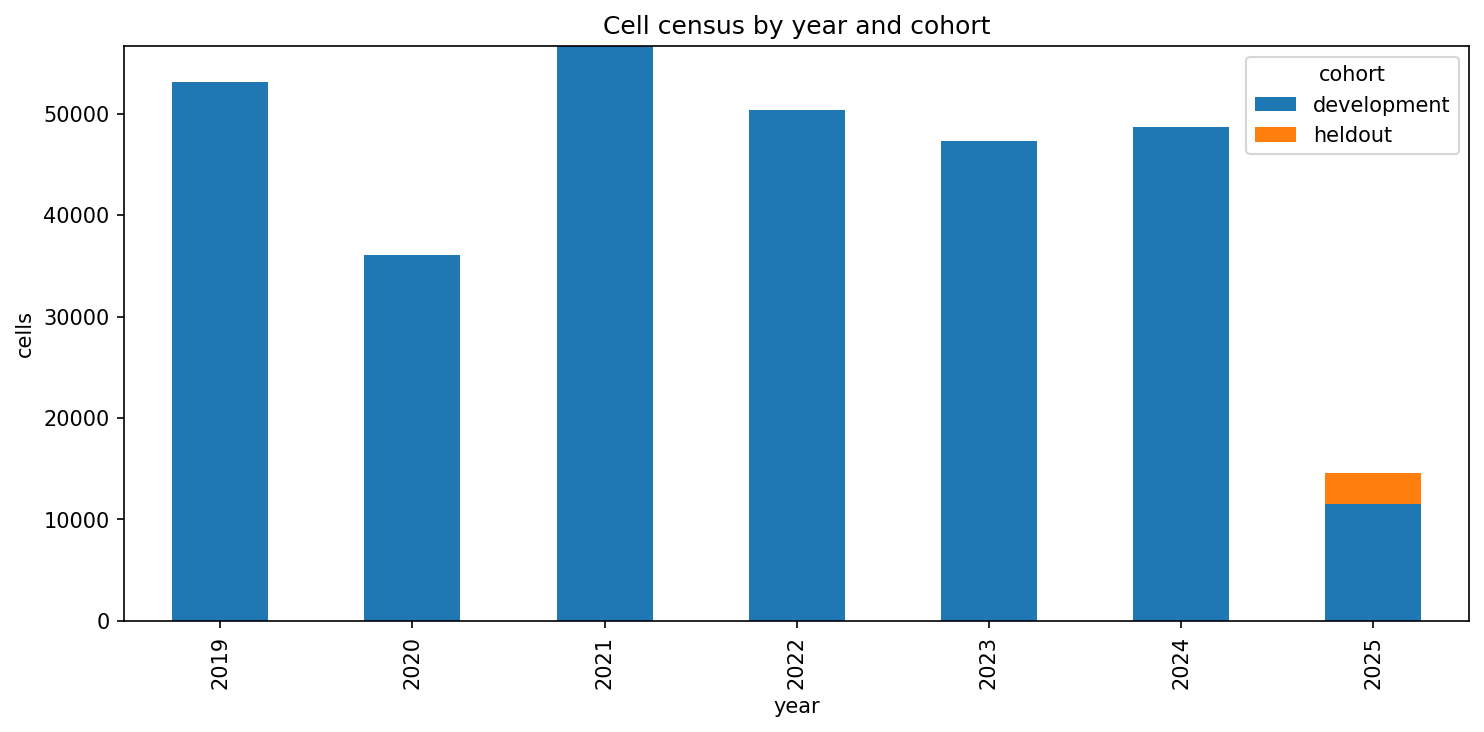

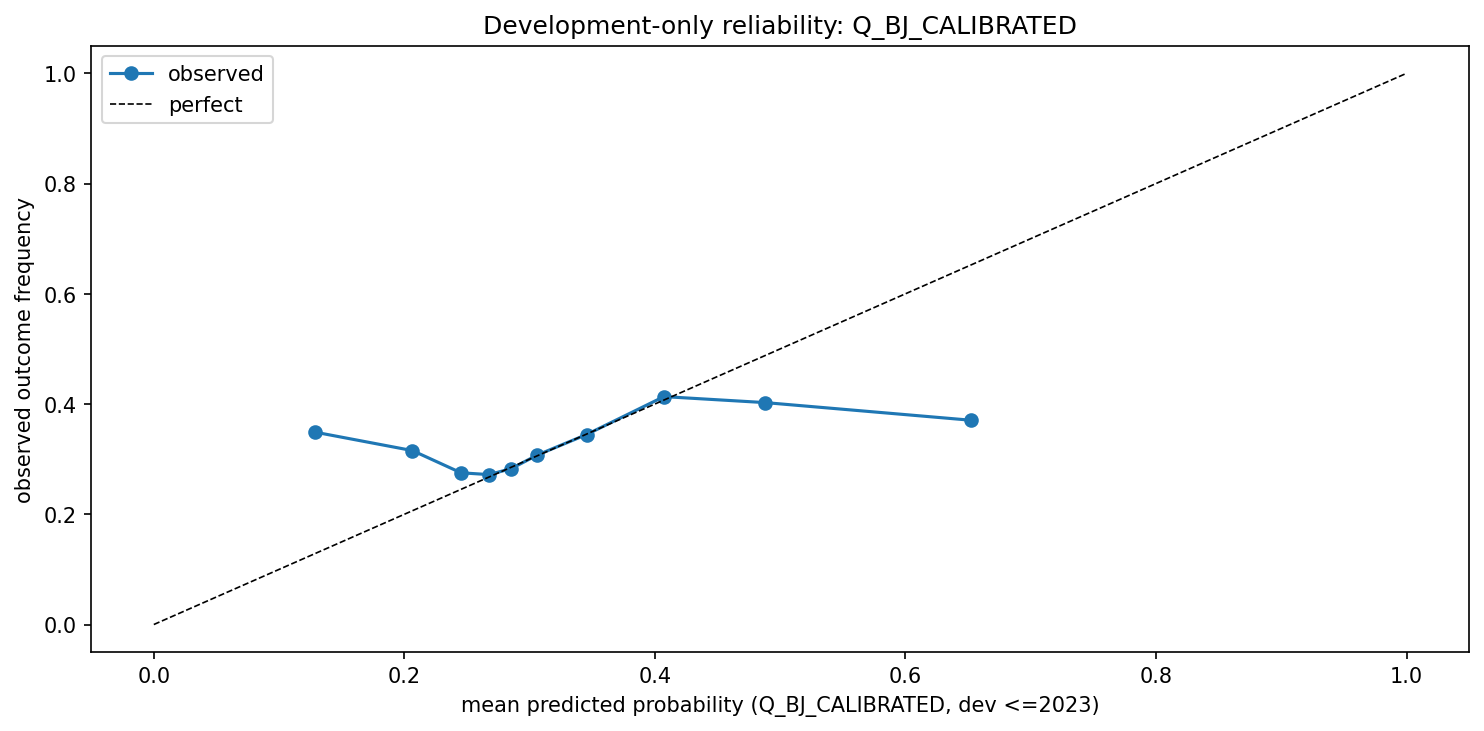

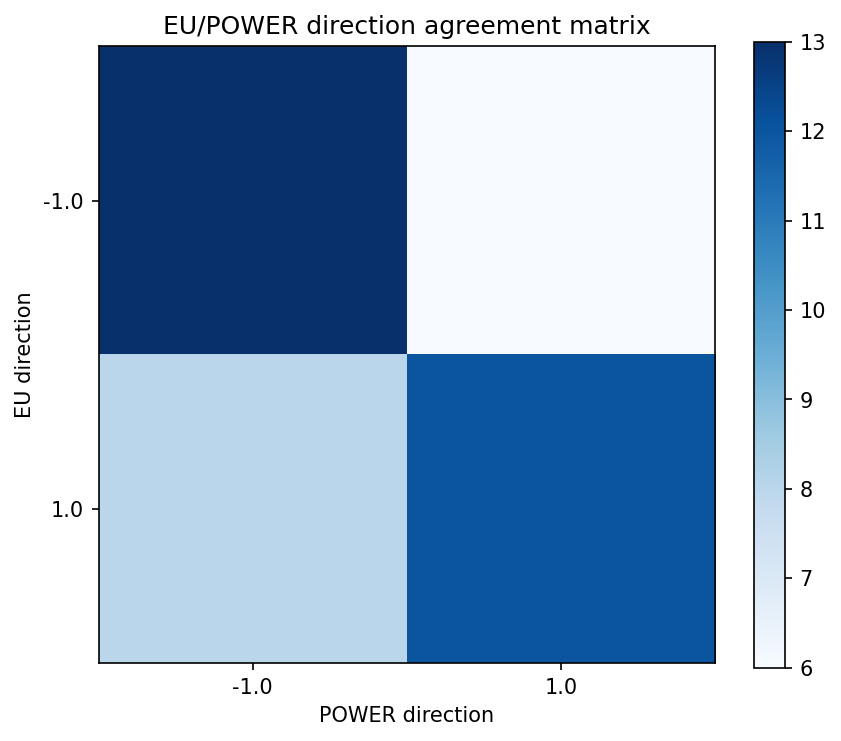

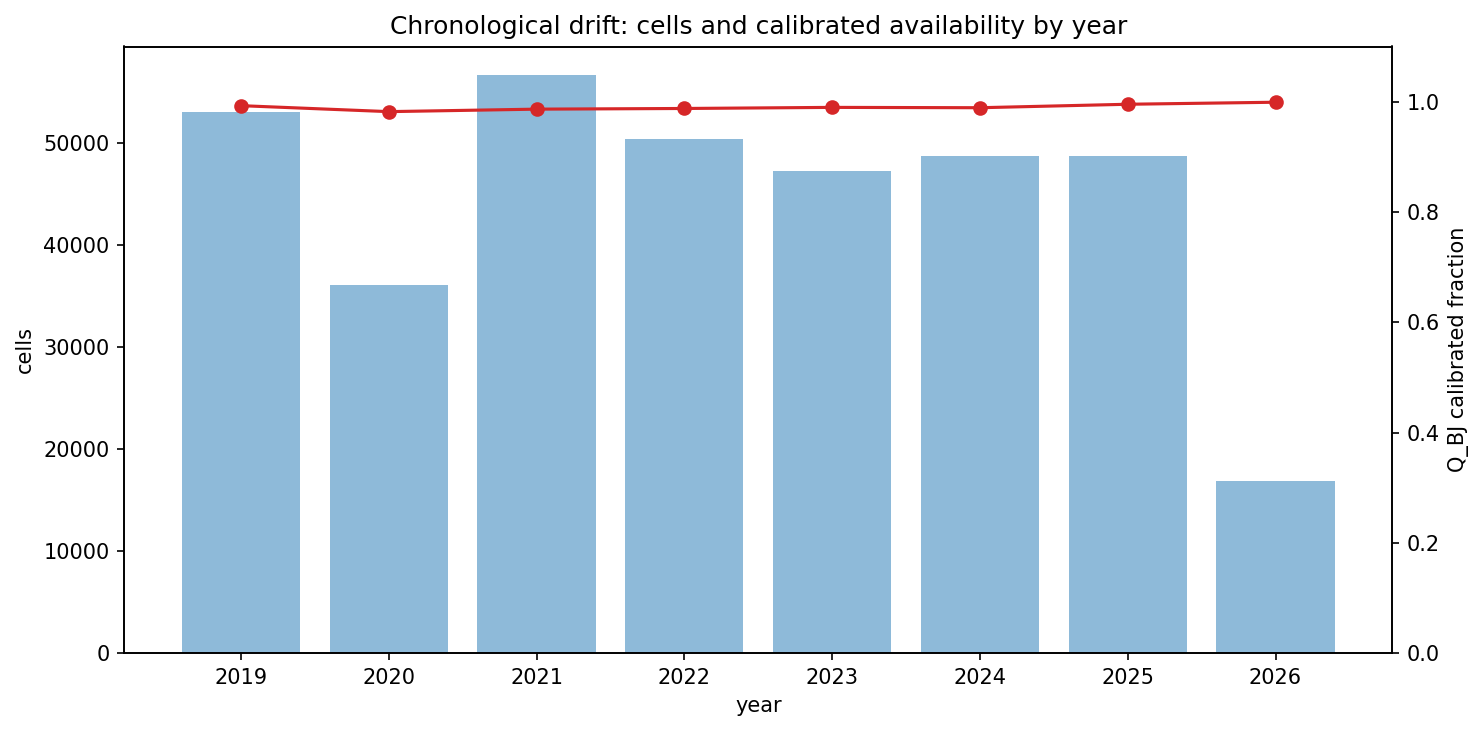

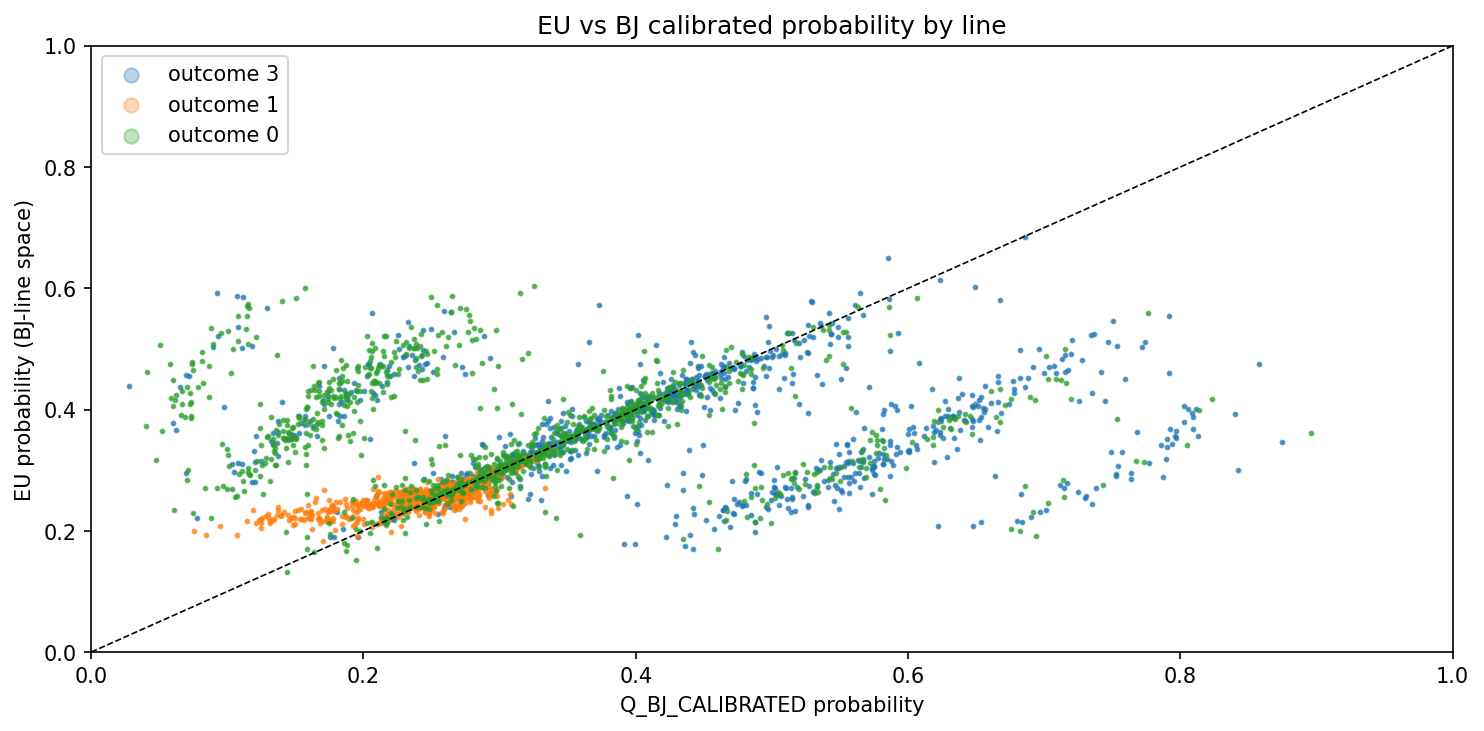

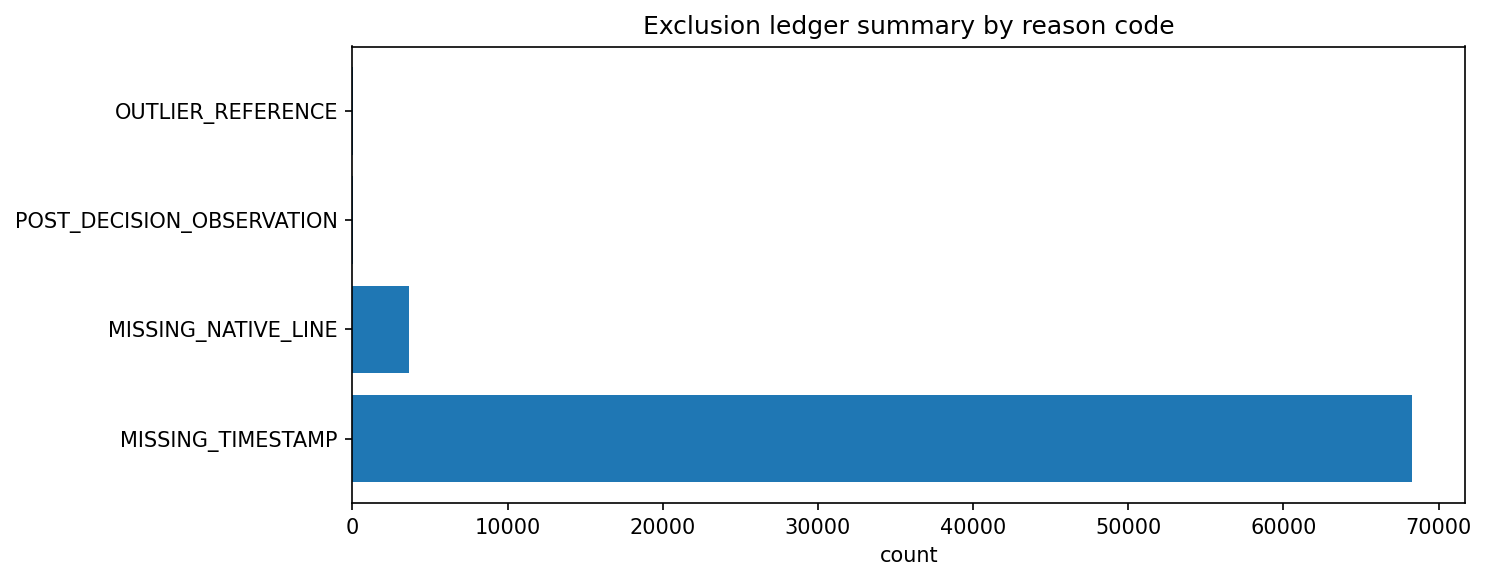

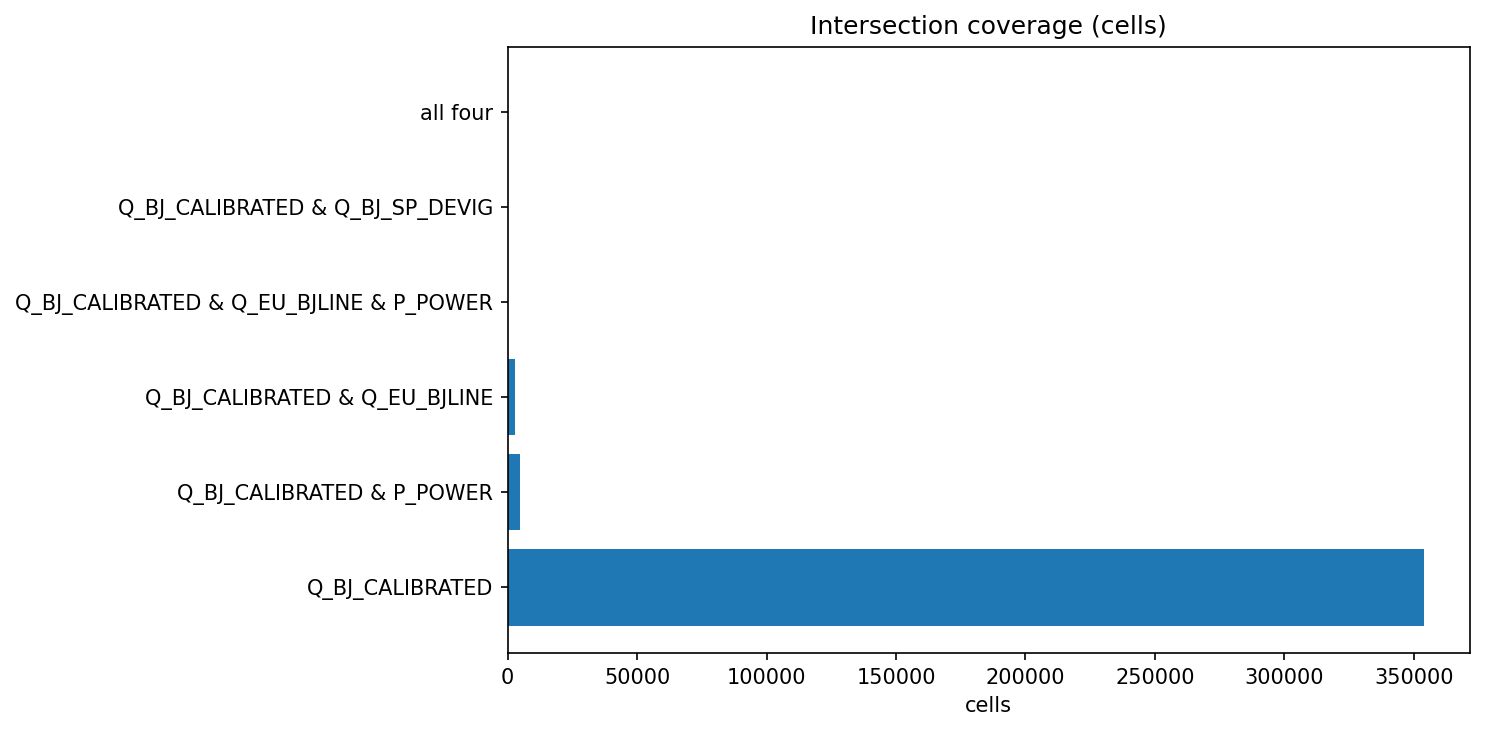

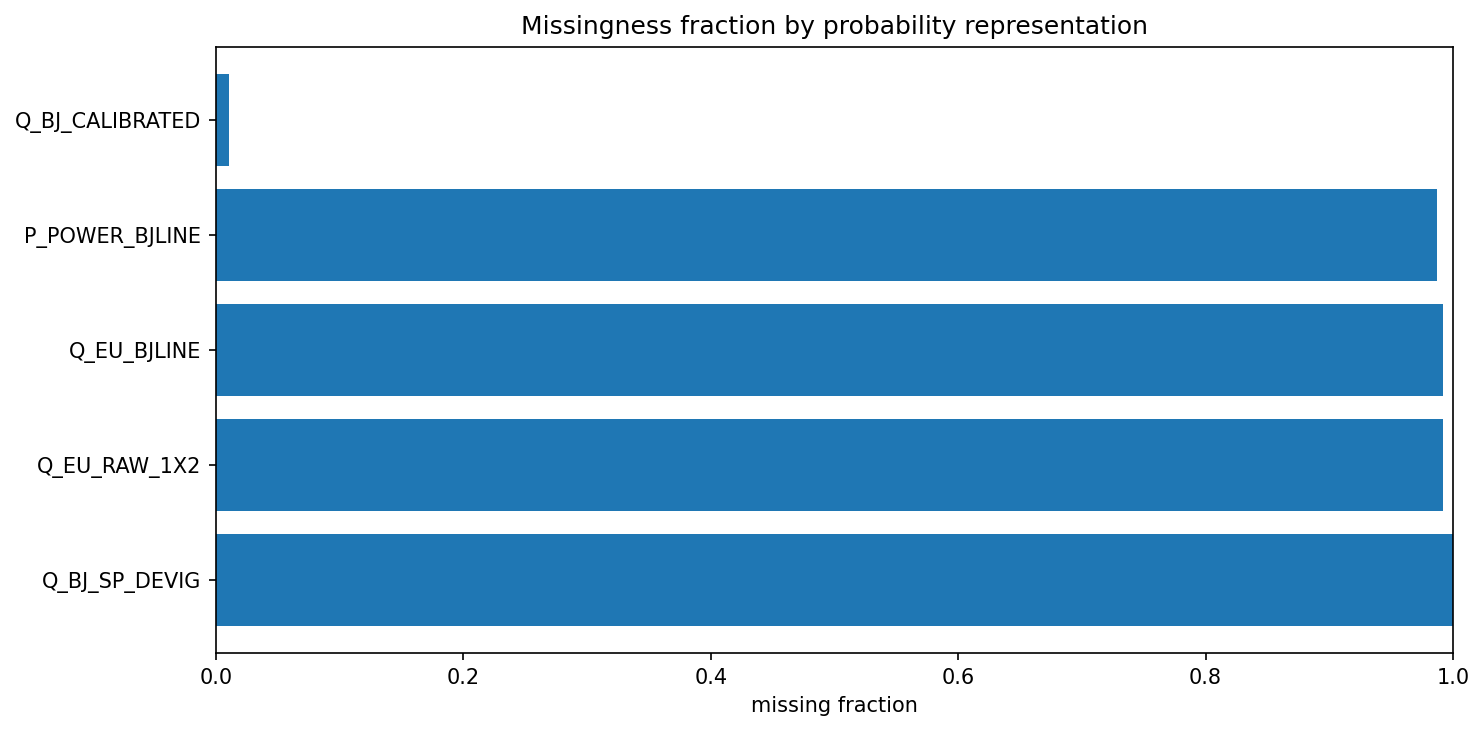

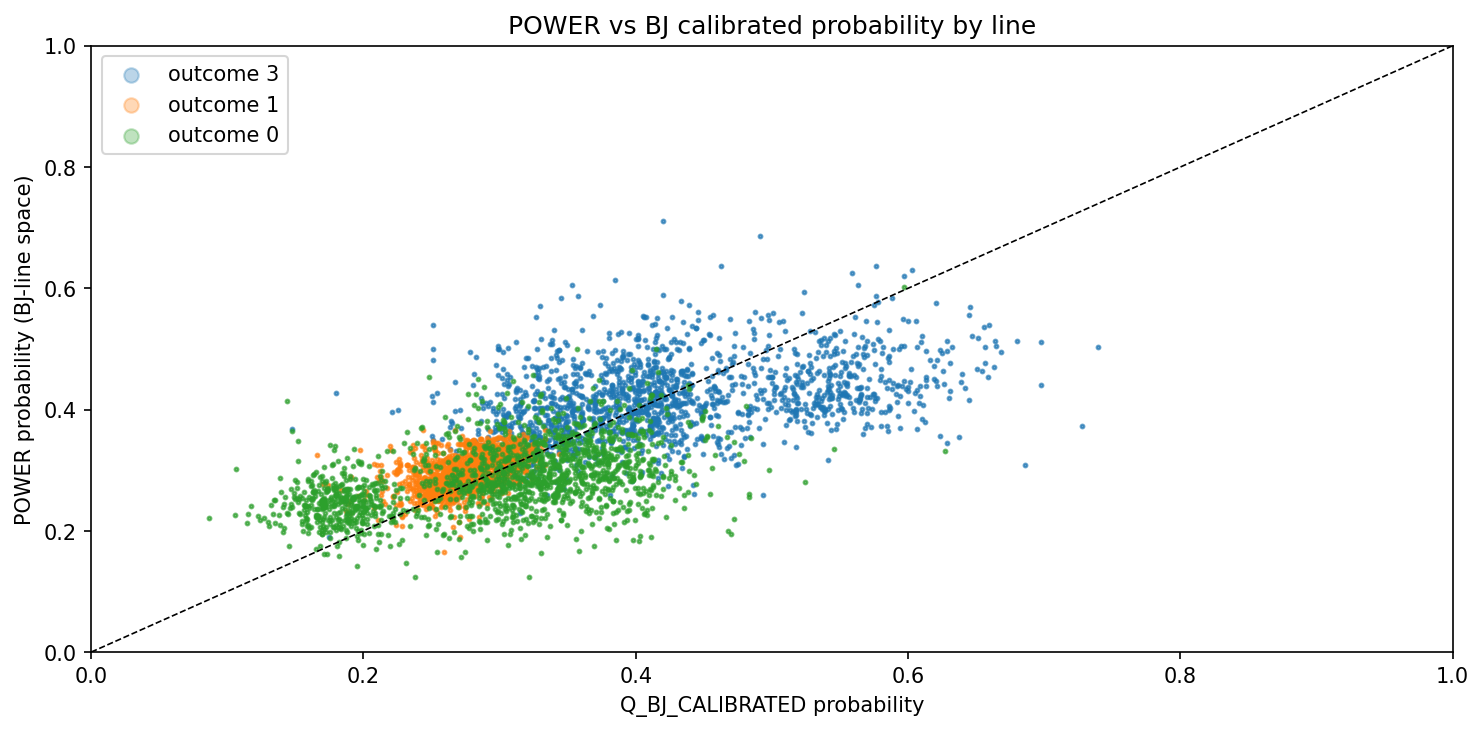

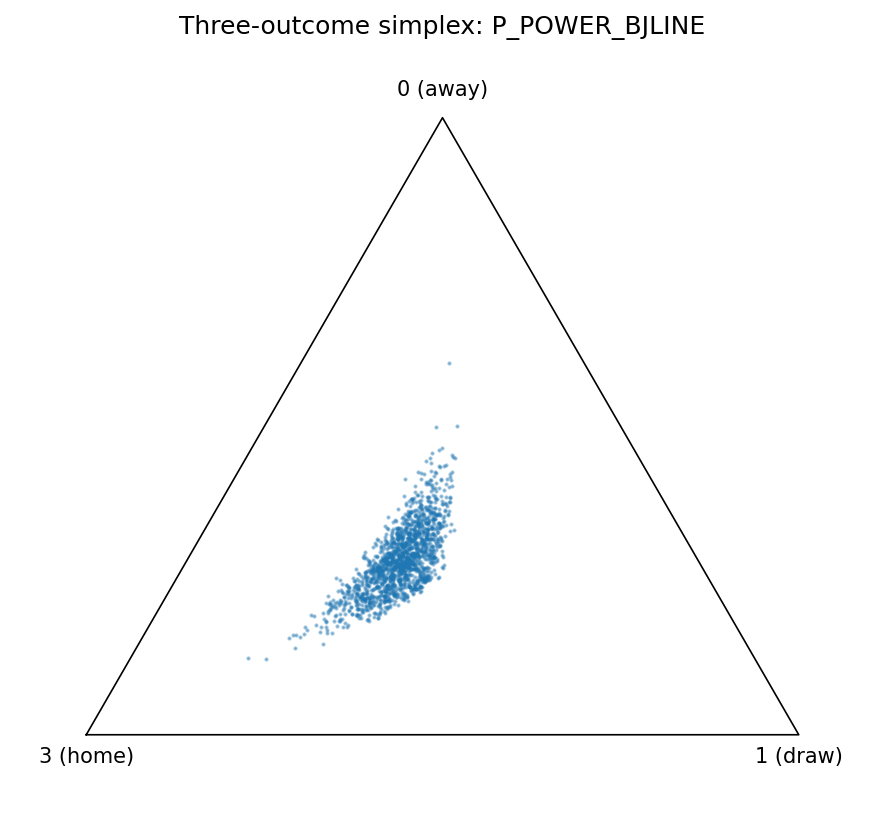

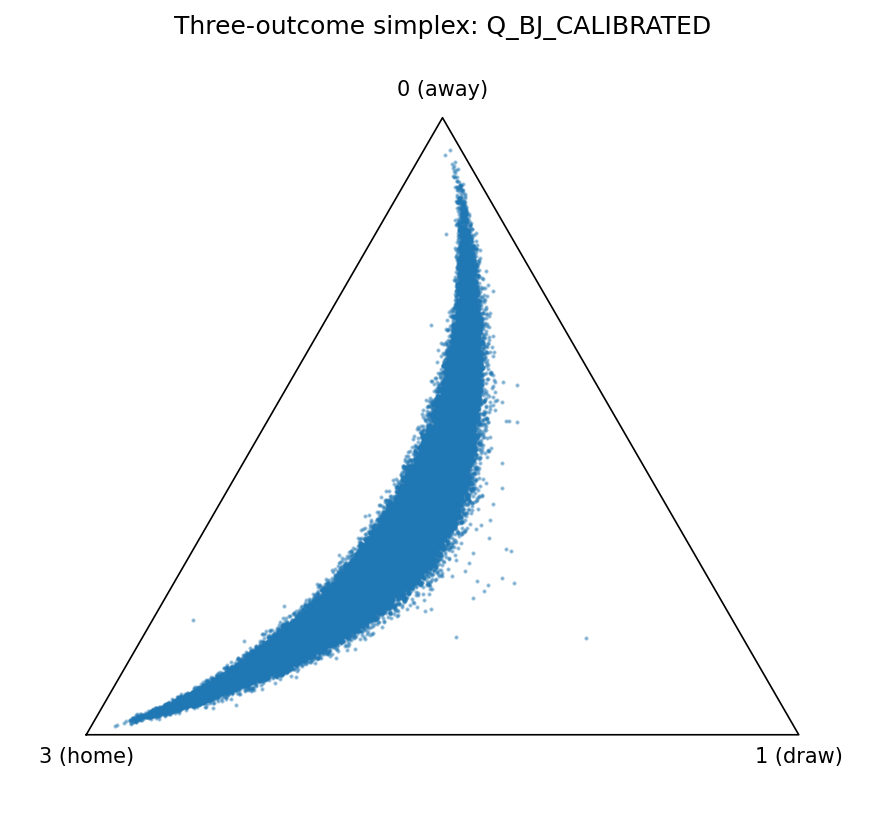

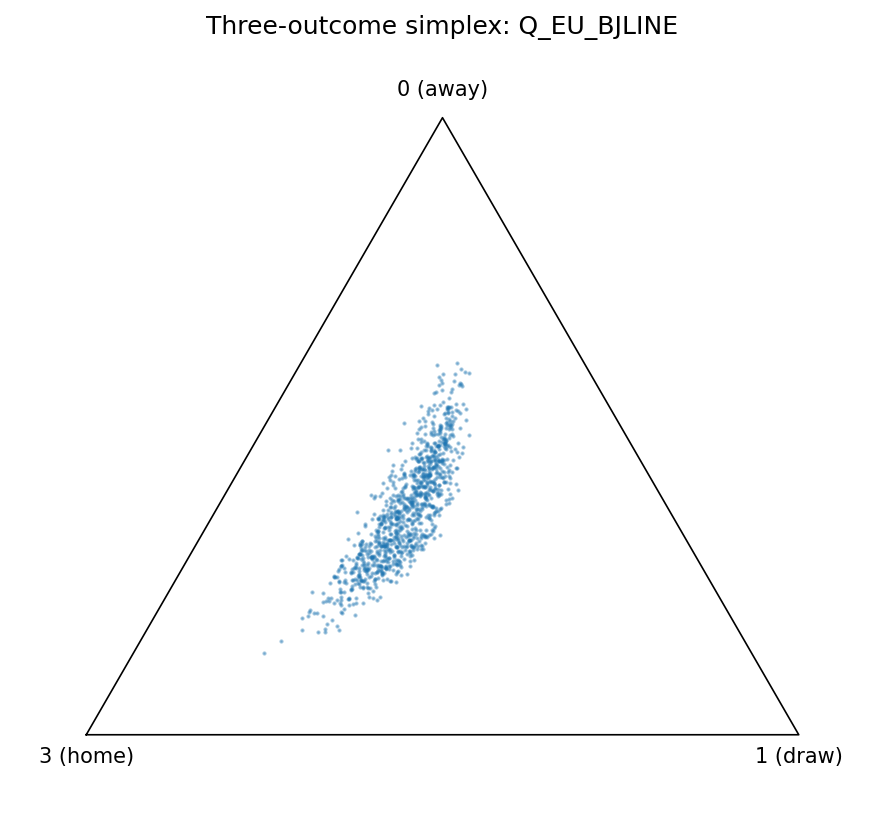

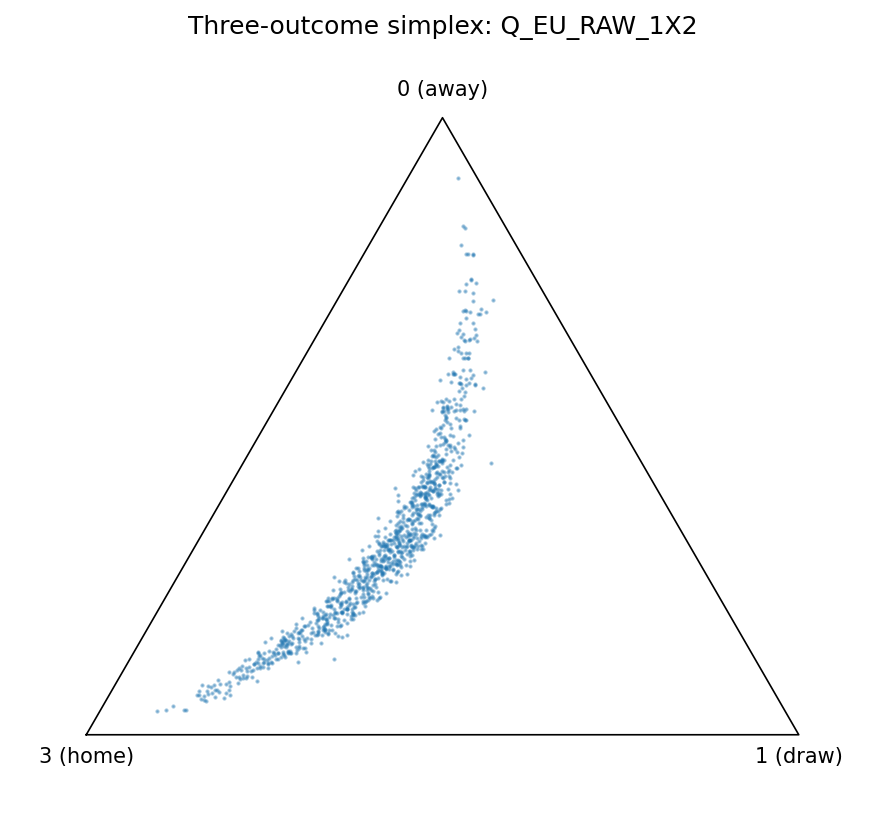

In [11]:
from IPython.display import Image as IPImage
import os

figures_dir = target / "figures"
for name in sorted(os.listdir(figures_dir)):
    if name.endswith(".png"):
        display(IPImage(filename=str(figures_dir / name)))

## Package verification

Fail-closed verification: every file under the package matches
SHA256SUMS.json, the handoff schema validates, and the REQ-D evidence
closure holds (no READY_FOR_209 with failed requirements).

In [12]:
hashes = sources.verify_package_hashes(target)
print(f"VERIFIED {target}: {len(hashes)} files match SHA256SUMS.json")
import json
schema = json.loads((target / "handoff_schema.json").read_text())
print("handoff schema columns:", len(schema.get("columns", [])))
print("reviewed commit:", json.loads((target / "MANIFEST.json").read_text()).get("reviewed_commit_sha"))

VERIFIED /home/drwho1985/workspace/soccer/beijing-lot-bj229/results/bj229_divergence_profile_v1: 60 files match SHA256SUMS.json
handoff schema columns: 65
reviewed commit: 27e05ee2e079d26510ece1f78b9fe0e0c9ea1a8b


## Readiness disposition

`READY_FOR_209`, `READY_WITH_EXPLICIT_LIMITATIONS` or `BLOCKED_DATA_DEFECT`
— chosen by consuming the DQ failures, never hardcoded.

In [13]:
print("disposition:", receipt.disposition)

disposition: READY_WITH_EXPLICIT_LIMITATIONS
